# hidden=32 vs hidden=64 — Phase & ECE Evaluation

Loads both GCNSimple and GAT checkpoints (`hidden=64` from `gcn_simple.pt` / `gat.pt`
and `hidden=32` from `gcn_simple_32.pt` / `gat_32.pt`) for **all eight maps** and
evaluates them across three phases:

- **Full-round** — all test states
- **Late pre-plant** — game states ≥ 85 s since phase start, before bomb plant
- **Post-plant** — all states after a successful bomb plant

Metrics reported: **Log Loss (LL)** and **ECE** for every model × map × phase cell.

**Prerequisite:** run Sections 0–2 of the canonical `training_notebook.ipynb` for
each map to build the preprocessed datasets in memory, *or* load them from disk
if you have saved them. The test_data dict and datasets dict must be available
in the session before running Section 3 of this notebook.

Alternatively, run this notebook **standalone** per map by setting MAP_NAME
in Section 0 and running top-to-bottom — it will load the processed match data
from Google Drive, build the test dataset, and evaluate both checkpoints.

## 0. Imports & Config

In [1]:
# ── install / mount ────────────────────────────────────────────────────────
!pip install torch_geometric -q

import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge
from sklearn.metrics import log_loss

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, flatten_to_states,
    GraphDataset, build_datasets,
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


In [2]:
# ── Edit this block when running a new map ────────────────────────────────
MAP_NAME = 'anubis'   # dust2 | mirage | train | nuke | ancient | anubis | overpass | inferno

CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
LATE_THRESHOLD = 85   # seconds since phase start — consistent with training_notebook
ECE_BINS       = 10
BATCH_SIZE     = 32

# Regularisation config — must match values used at training time
GRAPH_CFG = dict(
    hidden       = 64,    # used for gcn_simple.pt / gat.pt
    dropout_gcn  = 0.5,
    dropout_gat  = 0.3,
    drop_edge_p  = 0.5,
)
GRAPH_CFG_32 = dict(
    hidden       = 32,    # used for gcn_simple_32.pt / gat_32.pt
    dropout_gcn  = 0.5,
    dropout_gat  = 0.3,
    drop_edge_p  = 0.5,
)

print(f'Map: de_{MAP_NAME}')
print(f'Checkpoint dir: {CHECKPOINT_DIR}')

Map: de_anubis
Checkpoint dir: /content/drive/MyDrive/magisterka/checkpoints/anubis


## 1. Model Definitions

Copied verbatim from `training_notebook.ipynb` — do not modify.

In [3]:
class GCNSimple(nn.Module):
    def __init__(self, hidden=64, num_node_features=32, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        self.conv1 = GCNConv(num_node_features + 2, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        n   = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        ones     = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), ones)
        count = count.clamp(min=1)
        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew    = ea[:, 0].clamp(max=10.0)
        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, ew)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, ew)))
        return self.mlp(global_mean_pool(x_aug, batch))


class GAT(nn.Module):
    def __init__(self, hidden=64, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))


print('Model classes defined.')

Model classes defined.


## 2. Load Data

If `test_data` and `datasets` are already in scope from `training_notebook.ipynb`,
skip to Section 3. Otherwise run the cell below to load them from Drive.

In [4]:
from tqdm import tqdm
PROCESSED_DIR  = BASE / 'data'        / MAP_NAME
CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'
def get_tournament(match_key: str) -> str:
    parts = match_key.split('_')
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]

def load_season(season_dir: Path) -> dict:
    data = {}
    if not season_dir.exists():
        print(f'  ⚠️  {season_dir} not found — skipping')
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json')), desc=str(season_dir.name)):
        with open(fname) as f:
            data.update(json.load(f))
    return data

print('Loading data...')
s1_data = load_season(S1_DIR)
s2_data = load_season(S2_DIR)
print(f'Season 1: {len(s1_data):,} matches')
print(f'Season 2: {len(s2_data):,} matches')

s2_tournaments = sorted({get_tournament(k) for k in s2_data})
print(f'\nSeason 2 tournaments ({len(s2_tournaments)} total):')
for t in s2_tournaments:
    n = sum(1 for k in s2_data if get_tournament(k) == t)
    print(f'  {n:3d} matches  |  {t}')


Loading data...
  ⚠️  /content/drive/MyDrive/magisterka/data/anubis/season1 not found — skipping


season2: 100%|██████████| 156/156 [01:56<00:00,  1.33it/s]

Season 1: 0 matches
Season 2: 156 matches

Season 2 tournaments (31 total):
    1 matches  |  Asian Champions League
    6 matches  |  BLAST Bounty Season 1
    5 matches  |  BLAST Bounty Season 1 Finals
    6 matches  |  BLAST Major
    3 matches  |  BLAST Major Playoffs
    6 matches  |  BLAST Major Stage 1
    6 matches  |  BLAST Major Stage 2
   10 matches  |  BLAST Open Lisbon
    2 matches  |  BLAST Open Lisbon Playoffs
    1 matches  |  BLAST Rivals Season 1 Groups
    1 matches  |  BLAST Rivals Season 1 Playoffs
    6 matches  |  CCT Global Finals
    3 matches  |  ESL Pro League Season 21 Playoffs
   16 matches  |  ESL Pro League Season 21 Stage 1
    7 matches  |  ESL Pro League Season 21 Stage 2
    6 matches  |  FISSURE Playground 1
    1 matches  |  FISSURE Playground 1 Playoffs
    7 matches  |  IEM Dallas
    6 matches  |  IEM Katowice
    5 matches  |  IEM Katowice Play-in
    1 matches  |  IEM Katowice Playoffs
    8 matches  |  IEM Melbourne
    1 matches  |  IEM Melb

In [5]:
TOURNAMENT_SPLIT = {
   "BLAST Bounty Season 1": "train",
   "BLAST Bounty Season 1 Finals": "train",
   "IEM Katowice Play-in": "train",
   "IEM Katowice": "train",
   "IEM Katowice Playoffs": "train",
   "PGL Cluj-Napoca": "train",
   "ESL Pro League Season 21 Stage 1": "train",
   "ESL Pro League Season 21 Stage 2": "train",
  "ESL Pro League Season 21 Playoffs": "train",
   "BLAST Open Lisbon": "train",
   "BLAST Open Lisbon Playoffs":"train",
"PGL Bucharest": "train",
   "PGL Bucharest Playoffs": "train",
   "YaLLa Compass Groups":"train",
   "YaLLa Compass Playoffs":"train",
    "IEM Melbourne": "train",
   "IEM Melbourne Playoffs": "train",
   "CCT Global Finals":"train",
  "MESA Nomadic Masters Groups":"train",
    "BLAST Rivals Season 1 Groups": "train",
   "BLAST Rivals Season 1 Playoffs": "train",
   "Asian Champions League":"train",

    "PGL Astana": "val",
   "PGL Astana Playoffs": "val",
    "IEM Dallas": "val",
   "BLAST Major Stage 1": "val",

   "BLAST Major Stage 2": "test",
   "BLAST Major": "test",
   "BLAST Major Playoffs": "test",
   "FISSURE Playground 1": "test",
   "FISSURE Playground 1 Playoffs": "test",
}

train_data, val_data, test_data = dict(s1_data), {}, {}
unassigned = []
for key, match in s2_data.items():
    t = get_tournament(key)
    split = TOURNAMENT_SPLIT.get(t)
    if   split == 'train': train_data[key] = match
    elif split == 'val':   val_data[key]   = match
    elif split == 'test':  test_data[key]  = match
    else:                  unassigned.append((t, key))

if unassigned:
    print(f'⚠️  {len(unassigned)} unassigned — add to TOURNAMENT_SPLIT:')
    for t, _ in sorted(set((t, '') for t, _ in unassigned)): print(f'   {t}')

def count_rounds(d): return sum(len({r.get('roundNum') for r in v['df']}) for v in d.values())
def count_states(d): return sum(len(v['Y']) for v in d.values())

print(f'\n=== Split Summary — de_{MAP_NAME} ===')
for name, d in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    print(f'  {name:<5}: {len(d):4d} matches | {count_rounds(d):>6,} rounds | {count_states(d):>10,} states')



=== Split Summary — de_anubis ===
  Train:  107 matches |  2,293 rounds |    269,470 states
  Val  :   27 matches |    576 rounds |     66,053 states
  Test :   22 matches |    451 rounds |     52,445 states


In [6]:
datasets = build_datasets(
    train_data, val_data, test_data,
    temporal=False
)
normaliser_path = CHECKPOINT_DIR / 'normaliser'
datasets['set']['normaliser'].save(str(normaliser_path))
print(f'Datasets ready. Normaliser saved → {normaliser_path}.npz')


Datasets ready. Normaliser saved → /content/drive/MyDrive/magisterka/checkpoints/anubis/normaliser.npz


## 3. Helper Functions

In [7]:
def compute_ece(y_true, y_prob, n_bins=ECE_BINS):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0:
            continue
        ece += mask.sum() / n * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def compute_ece_on_mask(y_true, y_prob, mask, n_bins=ECE_BINS):
    """ECE restricted to a boolean index mask."""
    return compute_ece(y_true[mask], y_prob[mask], n_bins)


@torch.no_grad()
def predict_graph(model, loader):
    model.eval()
    probs, trues = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy().flatten())
        trues.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


def load_graph_model(model_class, cfg, ckpt_name):
    """Instantiate model_class with cfg, load weights from CHECKPOINT_DIR/ckpt_name."""
    if model_class is GCNSimple:
        m = model_class(
            hidden      = cfg['hidden'],
            dropout     = cfg['dropout_gcn'],
            drop_edge_p = cfg['drop_edge_p'],
        ).to(DEVICE)
    else:  # GAT
        m = model_class(
            hidden      = cfg['hidden'],
            dropout     = cfg['dropout_gat'],
            drop_edge_p = cfg['drop_edge_p'],
        ).to(DEVICE)
    ckpt = CHECKPOINT_DIR / ckpt_name
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    m.eval()
    print(f'  Loaded {ckpt_name}  (hidden={cfg["hidden"]})')
    return m


def build_time_and_bomb_arrays(test_data):
    """Build time_arr and bomb_arr aligned with the graph test loader order."""
    time_arr, bomb_arr = [], []
    for match in test_data.values():
        for df_row in match['df']:
            time_arr.append(float(df_row.get('secondsSincePhaseStart', 0)))
            bomb_arr.append(int(df_row.get('bombPlanted', 0)))
    return np.array(time_arr), np.array(bomb_arr)


def phase_report(label, y_true, y_prob, time_arr, bomb_arr, late_threshold=LATE_THRESHOLD):
    """Print LL and ECE for full-round, late pre-plant, and post-plant phases."""
    pre_plant_mask  = (bomb_arr == 0)
    late_mask       = pre_plant_mask & (time_arr >= late_threshold)
    post_plant_mask = (bomb_arr == 1)

    results = {}
    for phase, mask in [
        ('full',       np.ones(len(y_true), dtype=bool)),
        ('late_pre',   late_mask),
        ('post_plant', post_plant_mask),
    ]:
        if mask.sum() < 10:
            results[phase] = {'ll': float('nan'), 'ece': float('nan'), 'n': 0}
            continue
        ll  = log_loss(y_true[mask], y_prob[mask])
        ece = compute_ece(y_true[mask], y_prob[mask])
        results[phase] = {'ll': ll, 'ece': ece, 'n': int(mask.sum())}

    n_late = results['late_pre']['n']
    n_post = results['post_plant']['n']
    print(f'  {label:<16}  '
          f'Full: LL={results["full"]["ll"]:.4f} ECE={results["full"]["ece"]:.4f}  |  '
          f'Late pre-plant (n={n_late:,}): LL={results["late_pre"]["ll"]:.4f} ECE={results["late_pre"]["ece"]:.4f}  |  '
          f'Post-plant (n={n_post:,}): LL={results["post_plant"]["ll"]:.4f} ECE={results["post_plant"]["ece"]:.4f}')
    return results


print('Helpers defined.')

Helpers defined.


## 4. Load Checkpoints & Evaluate

In [8]:
test_loader = PyGLoader(
    datasets['graph']['test'],
    batch_size=BATCH_SIZE,
    shuffle=False,
)

time_arr, bomb_arr = build_time_and_bomb_arrays(test_data)
print(f'Time/bomb arrays: {len(time_arr):,} states')

# Sanity check: graph loader length must match time_arr
n_graph = sum(b.y.shape[0] for b in PyGLoader(datasets['graph']['test'], batch_size=BATCH_SIZE, shuffle=False))
assert n_graph == len(time_arr), f'LENGTH MISMATCH: graph={n_graph} time_arr={len(time_arr)}'
print(f'Graph loader length matches time_arr ✓')

Time/bomb arrays: 52,445 states
Graph loader length matches time_arr ✓


In [9]:
print(f'\n=== de_{MAP_NAME} — Phase × ECE Breakdown ===')
print(f'Late pre-plant threshold: ≥ {LATE_THRESHOLD} s')
print()

all_results = {}   # (model_label) -> phase_results dict

for arch_name, ModelClass, ckpt_64, ckpt_32 in [
    ('GCNSimple', GCNSimple, 'gcn_simple.pt',    'gcn_simple_32.pt'),
    ('GAT',       GAT,       'gat.pt',            'gat_32.pt'),
]:
    print(f'── {arch_name} ──────────────────────────────────────────────')

    for label, cfg, ckpt in [
        (f'{arch_name}_64', GRAPH_CFG,    ckpt_64),
        (f'{arch_name}_32', GRAPH_CFG_32, ckpt_32),
    ]:
        ckpt_path = CHECKPOINT_DIR / ckpt
        if not ckpt_path.exists():
            print(f'  {label}: checkpoint not found at {ckpt_path} — skipping')
            continue

        model = load_graph_model(ModelClass, cfg, ckpt)
        loader = PyGLoader(datasets['graph']['test'], batch_size=BATCH_SIZE, shuffle=False)
        y_true, y_prob = predict_graph(model, loader)

        res = phase_report(label, y_true, y_prob, time_arr, bomb_arr)
        all_results[label] = res

    print()


=== de_anubis — Phase × ECE Breakdown ===
Late pre-plant threshold: ≥ 85 s

── GCNSimple ──────────────────────────────────────────────
  Loaded gcn_simple.pt  (hidden=64)
  GCNSimple_64      Full: LL=0.4628 ECE=0.0376  |  Late pre-plant (n=3,825): LL=0.4019 ECE=0.0495  |  Post-plant (n=9,661): LL=0.2251 ECE=0.0292
  Loaded gcn_simple_32.pt  (hidden=32)
  GCNSimple_32      Full: LL=0.4521 ECE=0.0177  |  Late pre-plant (n=3,825): LL=0.3759 ECE=0.0369  |  Post-plant (n=9,661): LL=0.2242 ECE=0.0271

── GAT ──────────────────────────────────────────────
  Loaded gat.pt  (hidden=64)
  GAT_64            Full: LL=0.4741 ECE=0.0161  |  Late pre-plant (n=3,825): LL=0.4489 ECE=0.0369  |  Post-plant (n=9,661): LL=0.2381 ECE=0.0349
  Loaded gat_32.pt  (hidden=32)
  GAT_32            Full: LL=0.4631 ECE=0.0216  |  Late pre-plant (n=3,825): LL=0.4263 ECE=0.0378  |  Post-plant (n=9,661): LL=0.2316 ECE=0.0252



## 5. Compact Summary Table

In [10]:
PHASES = ['full', 'late_pre', 'post_plant']
PHASE_LABELS = {'full': 'Full', 'late_pre': 'Late pre-plant', 'post_plant': 'Post-plant'}

for phase in PHASES:
    print(f'\n── {PHASE_LABELS[phase]} ──────────────────────────────────────────')
    print(f'{"Model":<18}  {"LL":>8}  {"ECE":>8}')
    print('-' * 38)
    for label, res in all_results.items():
        ll  = res[phase]['ll']
        ece = res[phase]['ece']
        ll_str  = f'{ll:.4f}'  if not np.isnan(ll)  else '    n/a'
        ece_str = f'{ece:.4f}' if not np.isnan(ece) else '    n/a'
        print(f'{label:<18}  {ll_str:>8}  {ece_str:>8}')


── Full ──────────────────────────────────────────
Model                     LL       ECE
--------------------------------------
GCNSimple_64          0.4628    0.0376
GCNSimple_32          0.4521    0.0177
GAT_64                0.4741    0.0161
GAT_32                0.4631    0.0216

── Late pre-plant ──────────────────────────────────────────
Model                     LL       ECE
--------------------------------------
GCNSimple_64          0.4019    0.0495
GCNSimple_32          0.3759    0.0369
GAT_64                0.4489    0.0369
GAT_32                0.4263    0.0378

── Post-plant ──────────────────────────────────────────
Model                     LL       ECE
--------------------------------------
GCNSimple_64          0.2251    0.0292
GCNSimple_32          0.2242    0.0271
GAT_64                0.2381    0.0349
GAT_32                0.2316    0.0252


## 6. ECE Calibration Curves by Phase

One panel per model pair (64 vs 32), one row per phase.

  Loaded gcn_simple.pt  (hidden=64)
  Loaded gcn_simple_32.pt  (hidden=32)
  Loaded gat.pt  (hidden=64)
  Loaded gat_32.pt  (hidden=32)


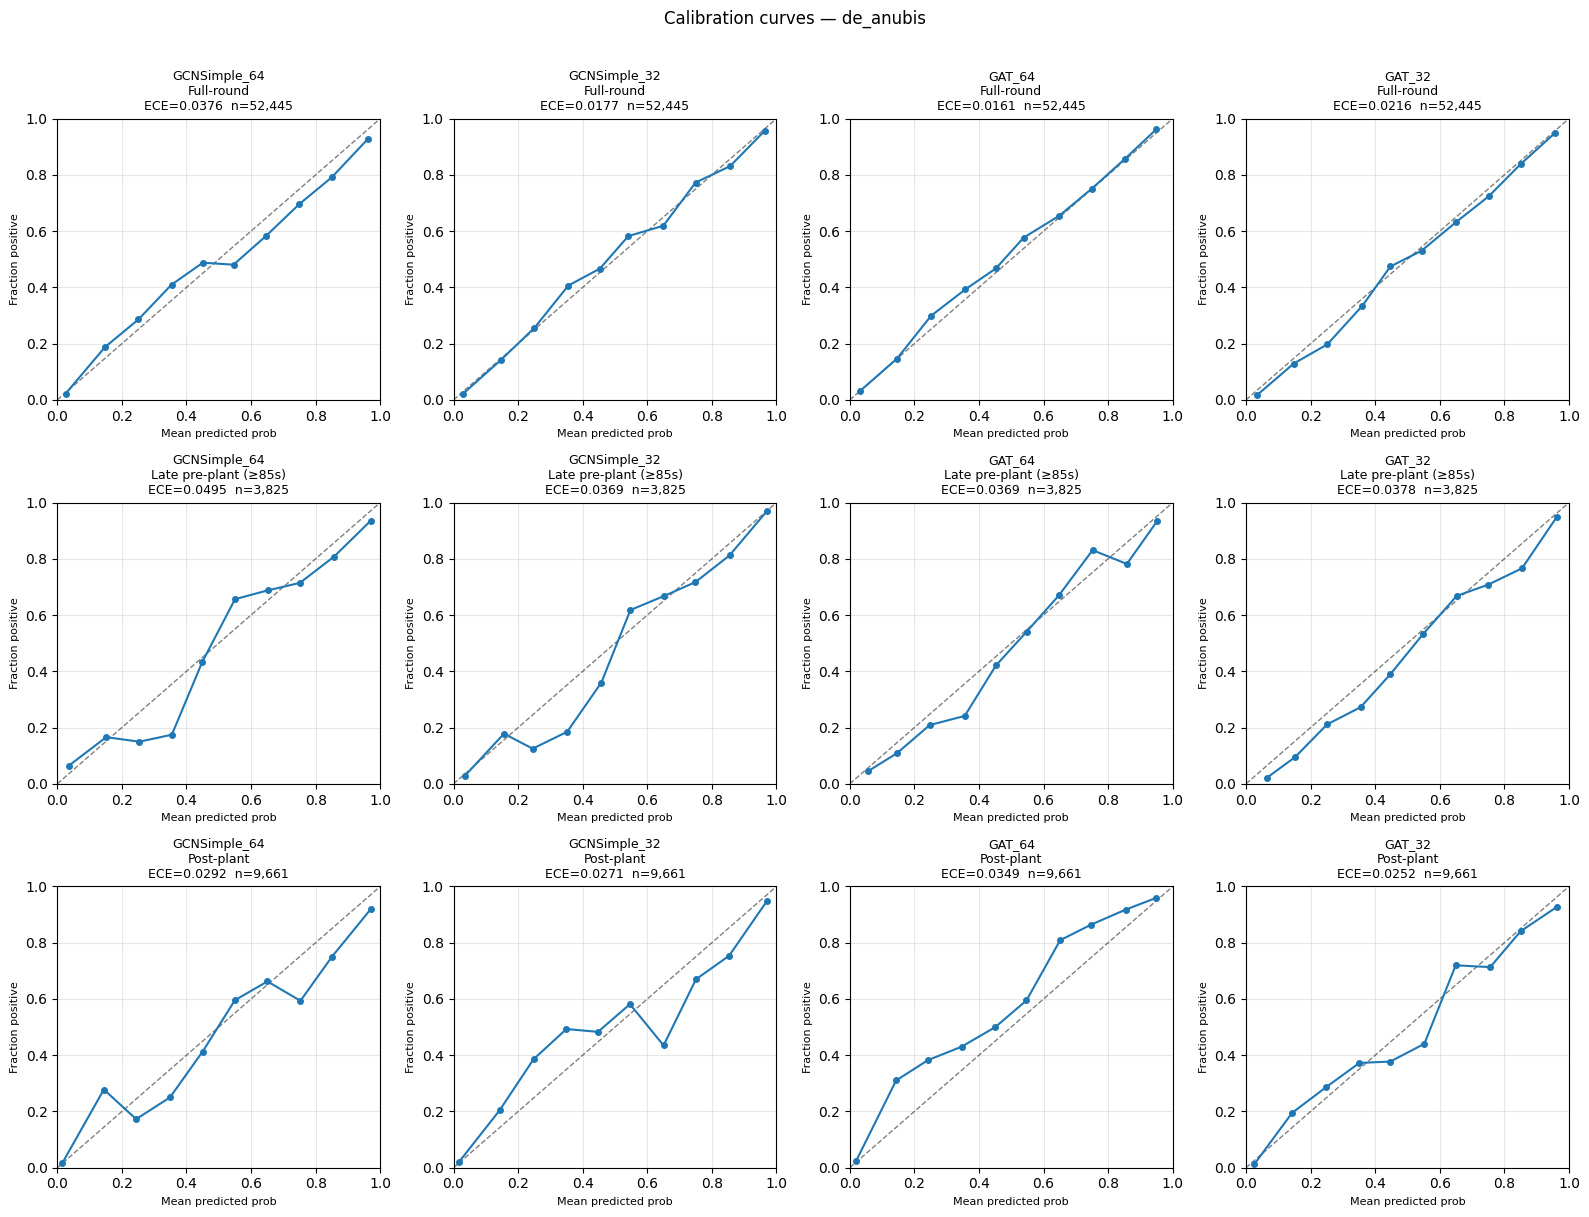

Saved → /content/drive/MyDrive/magisterka/checkpoints/anubis/fig_calibration_32vs64_by_phase.png


In [11]:
# Re-run predictions storing probabilities for plotting
pred_store = {}   # label -> (y_true, y_prob)

for arch_name, ModelClass, ckpt_64, ckpt_32 in [
    ('GCNSimple', GCNSimple, 'gcn_simple.pt', 'gcn_simple_32.pt'),
    ('GAT',       GAT,       'gat.pt',         'gat_32.pt'),
]:
    for label, cfg, ckpt in [
        (f'{arch_name}_64', GRAPH_CFG,    ckpt_64),
        (f'{arch_name}_32', GRAPH_CFG_32, ckpt_32),
    ]:
        if not (CHECKPOINT_DIR / ckpt).exists():
            continue
        model  = load_graph_model(ModelClass, cfg, ckpt)
        loader = PyGLoader(datasets['graph']['test'], batch_size=BATCH_SIZE, shuffle=False)
        pred_store[label] = predict_graph(model, loader)


def calibration_panel(ax, y_true, y_prob, mask, title, n_bins=ECE_BINS):
    """Reliability diagram on a subset defined by mask."""
    yt = y_true[mask]
    yp = y_prob[mask]
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_centers, frac_pos, frac_pred = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (yp >= lo) & (yp < hi)
        if m.sum() < 5:
            continue
        bin_centers.append((lo + hi) / 2)
        frac_pos.append(yt[m].mean())
        frac_pred.append(yp[m].mean())
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Perfect')
    ax.plot(frac_pred, frac_pos, 'o-', ms=4, lw=1.5)
    ece = compute_ece(yt, yp)
    ax.set_title(f'{title}\nECE={ece:.4f}  n={mask.sum():,}', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Mean predicted prob', fontsize=8)
    ax.set_ylabel('Fraction positive', fontsize=8)
    ax.grid(True, alpha=0.3)


pre_plant_mask  = (bomb_arr == 0)
late_mask       = pre_plant_mask & (time_arr >= LATE_THRESHOLD)
post_plant_mask = (bomb_arr == 1)

phase_masks  = [np.ones(len(bomb_arr), dtype=bool), late_mask, post_plant_mask]
phase_titles = ['Full-round', f'Late pre-plant (≥{LATE_THRESHOLD}s)', 'Post-plant']

labels_to_plot = [k for k in pred_store]
n_models = len(labels_to_plot)
n_phases = len(phase_masks)

fig, axes = plt.subplots(n_phases, n_models,
                         figsize=(4 * n_models, 4 * n_phases),
                         squeeze=False)

for col, label in enumerate(labels_to_plot):
    y_true, y_prob = pred_store[label]
    for row, (mask, ptitle) in enumerate(zip(phase_masks, phase_titles)):
        calibration_panel(axes[row][col], y_true, y_prob, mask,
                          title=f'{label}\n{ptitle}')

fig.suptitle(f'Calibration curves — de_{MAP_NAME}', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration_32vs64_by_phase.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {CHECKPOINT_DIR}/fig_calibration_32vs64_by_phase.png')

## 7. LL Difference Heatmap  (64 minus 32)

Positive = hidden=64 is *worse* (higher LL), meaning hidden=32 is better.
Negative = hidden=64 is *better*.

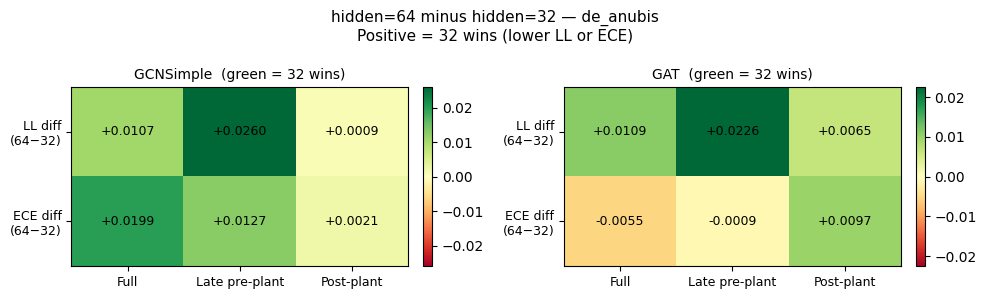

Saved → /content/drive/MyDrive/magisterka/checkpoints/anubis/fig_hidden_diff_heatmap.png


In [12]:
import matplotlib.colors as mcolors

phase_masks_ordered = [
    ('full',       np.ones(len(bomb_arr), dtype=bool)),
    ('late_pre',   late_mask),
    ('post_plant', post_plant_mask),
]

arch_pairs = [('GCNSimple', 'GCNSimple_64', 'GCNSimple_32'),
              ('GAT',       'GAT_64',       'GAT_32')]

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for ax, (arch, lbl64, lbl32) in zip(axes, arch_pairs):
    if lbl64 not in pred_store or lbl32 not in pred_store:
        ax.set_visible(False)
        continue

    yt64, yp64 = pred_store[lbl64]
    yt32, yp32 = pred_store[lbl32]

    diff_ll  = []
    diff_ece = []
    phase_names = []
    for pname, mask in phase_masks_ordered:
        if mask.sum() < 10:
            continue
        ll64  = log_loss(yt64[mask], yp64[mask])
        ll32  = log_loss(yt32[mask], yp32[mask])
        ece64 = compute_ece(yt64[mask], yp64[mask])
        ece32 = compute_ece(yt32[mask], yp32[mask])
        diff_ll.append(ll64 - ll32)     # + means 32 is better on LL
        diff_ece.append(ece64 - ece32)  # + means 32 is better on ECE
        phase_names.append(PHASE_LABELS[pname])

    data = np.array([diff_ll, diff_ece])  # shape (2, n_phases)
    vmax = max(abs(data).max(), 0.005)
    im = ax.imshow(data, cmap='RdYlGn', vmin=-vmax, vmax=vmax, aspect='auto')

    ax.set_xticks(range(len(phase_names)))
    ax.set_xticklabels(phase_names, fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['LL diff\n(64−32)', 'ECE diff\n(64−32)'], fontsize=9)
    ax.set_title(f'{arch}  (green = 32 wins)', fontsize=10)

    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            ax.text(c, r, f'{data[r, c]:+.4f}',
                    ha='center', va='center', fontsize=9,
                    color='black')

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(f'hidden=64 minus hidden=32 — de_{MAP_NAME}\n'
             f'Positive = 32 wins (lower LL or ECE)', fontsize=11)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_hidden_diff_heatmap.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {CHECKPOINT_DIR}/fig_hidden_diff_heatmap.png')

In [13]:
# ── Train / Val ECE and CT win rate ──────────────────────────────────────
# Runs inference on train and val graph datasets for all four checkpoints.
# Note: dropout and drop_edge are disabled at eval() time, so these are
# deterministic. Train ECE will be much lower than val/test — that gap
# IS the overfitting signal, especially visible for hidden=32 on small maps.

print(f'\n=== de_{MAP_NAME} — Train / Val ECE & CT Win Rate ===\n')

for split_name, graph_ds in [('train', datasets['graph']['train']),
                              ('val',   datasets['graph']['val']),
                             ('test', datasets['graph']['test'])
                             ]:
    loader = PyGLoader(graph_ds, batch_size=BATCH_SIZE, shuffle=False)

    # CT win rate — pull labels directly from the dataset, no model needed
    all_labels = np.concatenate([b.y.numpy() for b in
                                 PyGLoader(graph_ds, batch_size=BATCH_SIZE, shuffle=False)])
    ct_wr = all_labels.mean()
    print(f'{split_name.upper()}  CT win rate: {ct_wr:.4f}  ({ct_wr*100:.1f}%)  '
          f'n={len(all_labels):,}')
    print(f'  {"Model":<18}  {"LL":>8}  {"ECE":>8}')
    print(f'  {"-"*38}')

    for arch_name, ModelClass, ckpt_64, ckpt_32 in [
        ('GCNSimple', GCNSimple, 'gcn_simple.pt',  'gcn_simple_32.pt'),
        ('GAT',       GAT,       'gat.pt',          'gat_32.pt'),
    ]:
        for label, cfg, ckpt in [
            (f'{arch_name}_64', GRAPH_CFG,    ckpt_64),
            (f'{arch_name}_32', GRAPH_CFG_32, ckpt_32),
        ]:
            ckpt_path = CHECKPOINT_DIR / ckpt
            if not ckpt_path.exists():
                print(f'  {label:<18}  (checkpoint not found)')
                continue

            model = load_graph_model(ModelClass, cfg, ckpt)
            loader = PyGLoader(graph_ds, batch_size=BATCH_SIZE, shuffle=False)
            y_true, y_prob = predict_graph(model, loader)

            ll  = log_loss(y_true, y_prob)
            ece = compute_ece(y_true, y_prob)
            print(f'  {label:<18}  {ll:>8.4f}  {ece:>8.4f}')

    print()


=== de_anubis — Train / Val ECE & CT Win Rate ===

TRAIN  CT win rate: 0.4132  (41.3%)  n=269,470
  Model                     LL       ECE
  --------------------------------------
  Loaded gcn_simple.pt  (hidden=64)
  GCNSimple_64          0.4239    0.0205
  Loaded gcn_simple_32.pt  (hidden=32)
  GCNSimple_32          0.4319    0.0155
  Loaded gat.pt  (hidden=64)
  GAT_64                0.4492    0.0229
  Loaded gat_32.pt  (hidden=32)
  GAT_32                0.4537    0.0221

VAL  CT win rate: 0.4519  (45.2%)  n=66,053
  Model                     LL       ECE
  --------------------------------------
  Loaded gcn_simple.pt  (hidden=64)
  GCNSimple_64          0.4629    0.0274
  Loaded gcn_simple_32.pt  (hidden=32)
  GCNSimple_32          0.4561    0.0214
  Loaded gat.pt  (hidden=64)
  GAT_64                0.4864    0.0279
  Loaded gat_32.pt  (hidden=32)
  GAT_32                0.4722    0.0201

TEST  CT win rate: 0.4412  (44.1%)  n=52,445
  Model                     LL       ECE
  ---

## 8. Cross-Map Aggregation  *(run after all eight maps)*

After running Sections 0–7 for each map and collecting results, paste the
per-map numbers into the dicts below and run this cell to produce the
cross-map summary table used in the thesis.

In [ ]:
# ── Paste results here after running all 8 maps ───────────────────────────
# Format: map -> model -> phase -> {ll, ece}
# Example structure — fill in real numbers:

MAPS = ['dust2', 'mirage', 'train', 'nuke', 'ancient', 'anubis', 'overpass', 'inferno']
MODELS = ['GCNSimple_64', 'GCNSimple_32', 'GAT_64', 'GAT_32']
PHASE_KEYS = ['full', 'late_pre', 'post_plant']

# results[map][model][phase] = {'ll': ..., 'ece': ...}
# (populated from the output of Section 4 above, one map at a time)
results = {m: {mod: {p: {'ll': float('nan'), 'ece': float('nan')}
                     for p in PHASE_KEYS}
               for mod in MODELS}
           for m in MAPS}

# ── Print full cross-map table ────────────────────────────────────────────
for phase in PHASE_KEYS:
    print(f'\n=== {PHASE_LABELS[phase]} — LL ===')
    header = f'{"Model":<16}' + ''.join(f'  {m:>9}' for m in MAPS)
    print(header)
    print('-' * len(header))
    for model in MODELS:
        row = f'{model:<16}'
        for m in MAPS:
            v = results[m][model][phase]['ll']
            row += f'  {v:>9.4f}' if not np.isnan(v) else f'  {"n/a":>9}'
        print(row)

    print(f'\n=== {PHASE_LABELS[phase]} — ECE ===')
    print(header)
    print('-' * len(header))
    for model in MODELS:
        row = f'{model:<16}'
        for m in MAPS:
            v = results[m][model][phase]['ece']
            row += f'  {v:>9.4f}' if not np.isnan(v) else f'  {"n/a":>9}'
        print(row)